<a href="https://colab.research.google.com/github/tevfikaytekin/recommender_systems_course/blob/main/matrix_factorization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Note: This notebook is designed primarily for pedagogical purposes. The algorithms (like Stochastic and Batch Gradient Descent) and the cost function derivatives are implemented from scratch using basic Python dictionaries and loops. This explicit implementation makes the underlying mathematics of Matrix Factorization transparent and easier to understand. However, for real-world applications or larger datasets, this implementation has significant inefficiencies which can be improved using vectorization or by using libraries such as PyTorch.*

# Matrix Factorization

Matrix factorization is one of the state-of-the-art techniques used in recommender systems. Below you can find several different implementations.

Over the years many variations of matrix factorization have been proposed. The following formulation is the standard one and constitutes the foundation of many others. It can be extended in various ways, see for example [Advances in Collaborative Filtering](https://link.springer.com/chapter/10.1007/978-1-4899-7637-6_3).



Cost Function:
$$
J(\Theta) =  \sum_{u,i \in K} (r_{ui} - (\mu + b_u + b_i + q^T_ip_u))^2 + \lambda(||q_i||^2+||p_u||^2 + ||b_u||^2 + ||b_i||^2)
$$

where

- $r_{ui}$ is the rating of user $u$ for item $i$.
- $K$ is the set of $(u,i)$ pairs for which $r_{ui}$ is known.
- $q_i$, $p_u$ are latent factor vectors for items and users, respectively.
- $\lambda$ is the regularization parameter.
- $\mu$: The overall average rating across all items and users. This accounts for the general rating scale.
- $b_u$: The bias of user $u$. This captures how much user $u$ tends to rate higher or lower than the average, independent of specific items.
- $b_i$: The bias of item $i$. This captures how much item $i$ tends to be rated higher or lower than the average, independent of specific users.

To improve the accuracy of predictions, especially for sparse data, it's common to incorporate biases. These biases help capture systematic tendencies in ratings that are not explained by the latent factors.

With these biases, the predicted rating for user $u$ on item $i$ is now $\hat{r}_{ui} = \mu + b_u + b_i + q^T_ip_u$.



Typically the optimization done with gradient descent. To apply it we need to first find the partial derivative of the cost function with respect to latent variables and biases.

We can find the partial derivatives as:

$$
\frac{\partial J(\Theta)}{\partial p_{ku}}=-2\sum_{i \in I_u} e_{ui} q_{ki} + 2\lambda p_{ku}
$$
$$
\frac{\partial J(\Theta)}{\partial q_{ki}}=-2\sum_{u \in U_i} e_{ui} p_{ku} + 2\lambda q_{ki}
$$
$$
\frac{\partial J(\Theta)}{\partial b_u}=-2\sum_{i \in I_u} e_{ui} + 2\lambda b_u
$$
$$
\frac{\partial J(\Theta)}{\partial b_i}=-2\sum_{u \in U_i} e_{ui} + 2\lambda b_i
$$

Let's define the error $e_{ui} = r_{ui} - (\mu + b_u + b_i + q^T_ip_u)$.

For **stochastic gradient descent** the update rules for a single training example $(u,i)$ are:


$$
p_u \leftarrow p_u + \alpha (e_{ui}q_{i} - \lambda p_{u})
$$
$$
q_i \leftarrow q_i + \alpha (e_{ui}p_{u} - \lambda q_{i})
$$
$$
b_u \leftarrow b_u + \alpha (e_{ui} - \lambda b_u)
$$
$$
b_i \leftarrow b_i + \alpha (e_{ui} - \lambda b_i)
$$

For **batch gradient descent** the update rules are:

$$
p_u \leftarrow p_u + \alpha (\sum_{i \in I_u}e_{ui}q_{i} - \lambda p_{u})
$$
$$
q_i \leftarrow q_i + \alpha (\sum_{u \in U_i} e_{ui}p_{u} - \lambda q_{i})
$$
$$
b_u \leftarrow b_u + \alpha (\sum_{i \in I_u}e_{ui} - \lambda b_u)
$$
$$
b_i \leftarrow b_i + \alpha (\sum_{u \in U_i}e_{ui} - \lambda b_i)
$$

In the above equations $I_u$ is the set of items rated by user $u$ and $U_i$ is the set of users who rated item $i$.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from scipy.sparse import csr_matrix
import copy

Download the ml-latest-small dataset


In [ ]:
!wget --no-check-certificate https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
!unzip -o ml-latest-small.zip

--2026-10-13 18:10:40--  https://files.grouplens.org/datasets/movielens/ml-latest-small.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.96.204
Connecting to files.grouplens.org (files.grouplens.org)|128.101.96.204|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 978202 (955K) [application/zip]
Saving to: ‘ml-latest-small.zip’

ml-latest-small.zip 100%[===================>] 955.28K  3.22MB/s    in 0.3s    

2026-10-13 18:10:41 (3.22 MB/s) - ‘ml-latest-small.zip’ saved [978202/978202]

Archive:  ml-latest-small.zip
   creating: ml-latest-small/
  inflating: ml-latest-small/links.csv  
  inflating: ml-latest-small/tags.csv  
  inflating: ml-latest-small/ratings.csv  
  inflating: ml-latest-small/README.txt  
  inflating: ml-latest-small/movies.csv  


# Movielens dataset

We will use the smallest Movielens 100k Dataset which includes 100k preferences. A preference is a triple (user, item, rating). You can download this data set from
[https://grouplens.org/datasets/movielens/](https://grouplens.org/datasets/movielens/)

Note the sparsity of the dataset which shows that most of the user/item matrix is empty. This is a typical property of the datasets in this domain.

In [ ]:
prefs = pd.read_csv("ml-latest-small/ratings.csv", sep=",")

prefs.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [ ]:
n_users = prefs.iloc[:,0].unique().size
n_items = prefs.iloc[:,1].unique().size
n_prefs = prefs.iloc[:,1].size
users = prefs.iloc[:,0].unique()
items = prefs.iloc[:,1].unique()

print("Number of users:",n_users)
print("Number of items:",n_items)
print("Number of preferences:",n_prefs)
print("Sparsity:",n_prefs/(n_users*n_items))

Number of users: 610
Number of items: 9724
Number of preferences: 100836
Sparsity: 0.016999683055613623


### Error Function

Error is calculated by predicting the rating of a user and an item in the test set using the factor representations of users and items.

In [ ]:
def calc_error(X, u_factors, i_factors, mu, user_bias, item_bias):
    error = 0
    for i in range(X.shape[0]):
        u_idx = X.iloc[i,0]
        i_idx = X.iloc[i,1]
        prediction = mu + user_bias[u_idx] + item_bias[i_idx] + np.dot(u_factors[u_idx].T, i_factors[i_idx])
        error += np.abs(X.iloc[i,2] - prediction)
    return error/X.shape[0]


### Random Predictor Error

**Exercise**: What is the expected error of a random predictor given that the actual ratings are uniformly distributed between 1 and 5?

Below is a function for calculating this error experimentally.

In [ ]:
def random_predictor_error(X):
    error = 0
    for i in range(X.shape[0]):
        u_idx = X.iloc[i,0]
        i_idx = X.iloc[i,1]
        error += np.abs(X.iloc[i,2] - np.random.randint(1,6))
    return error/X.shape[0]

In [ ]:
print("Random predictor error: ", random_predictor_error(prefs))

Random predictor error:  1.4836566305684478


In [ ]:
n_factors = 5
item_factors = {}
user_factors = {}
user_bias = {}
item_bias = {}

mu = prefs.iloc[:,2].mean()

for r in range(n_prefs):
    u_id = prefs.iloc[r,0]
    i_id = prefs.iloc[r,1]

    user_bias[u_id] = 0.0
    item_bias[i_id] = 0.0

    user_factors[u_id] = np.random.rand(n_factors,1) - 0.5
    item_factors[i_id] = np.random.rand(n_factors,1) - 0.5

In [ ]:
print("Initial error: ", calc_error(prefs, user_factors, item_factors, mu, user_bias, item_bias))

Initial error:  [[0.84590484]]


In [ ]:
item_factors[10]

array([[-0.07742741],
       [ 0.13030964],
       [-0.00522609],
       [-0.04903681],
       [ 0.10417978]])

### Stochastic Gradient Descent

Following is the stochastic gradient algorithm which is popularized by [Simon Funk](https://sifter.org/simon/journal/20061211.html)

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

# 1. Initialize
n_factors = 5
item_factors = {}
user_factors = {}
user_bias = {}
item_bias = {}

# Calculate global mean
mu = prefs.iloc[:,2].mean()

# Initialize factors and biases
for r in range(prefs.shape[0]):
    u_id = prefs.iloc[r,0]
    i_id = prefs.iloc[r,1]

    user_bias[u_id] = 0.0
    item_bias[i_id] = 0.0

    user_factors[u_id] = np.random.rand(n_factors,1) - 0.5
    item_factors[i_id] = np.random.rand(n_factors,1) - 0.5

# 2. Split data
X_train, X_test = train_test_split(prefs, test_size=0.1)

# 3. Hyperparameters
alpha = 0.03
my_lambda = 0.1
n_iters = 5

# 4. Print initial error
print("Initial error: ", calc_error(X_train, user_factors, item_factors, mu, user_bias, item_bias))

# 5. SGD Loop
for t in range(n_iters):
    X_train = shuffle(X_train)
    for r in range(X_train.shape[0]):
        u = X_train.iloc[r,0]
        i = X_train.iloc[r,1]
        rating = X_train.iloc[r,2]

        # Prediction
        prediction = mu + user_bias[u] + item_bias[i] + np.dot(user_factors[u].T, item_factors[i])[0,0]
        error = rating - prediction

        # Update biases
        user_bias[u] += alpha * (error - my_lambda * user_bias[u])
        item_bias[i] += alpha * (error - my_lambda * item_bias[i])

        # Update latent factors
        # Store old values to use in update equations simultaneously
        u_f = user_factors[u].copy()
        i_f = item_factors[i].copy()

        user_factors[u] += alpha * (error * i_f - my_lambda * u_f)
        item_factors[i] += alpha * (error * u_f - my_lambda * i_f)

    print("Iteration ", t)
    print("Train error: ", calc_error(X_train, user_factors, item_factors, mu, user_bias, item_bias))
    print("Test error: ", calc_error(X_test, user_factors, item_factors, mu, user_bias, item_bias))

Initial error:  [[0.84691635]]
Iteration  0
Train error:  [[0.6676997]]
Test error:  [[0.68056283]]
Iteration  1
Train error:  [[0.64998422]]
Test error:  [[0.672366]]
Iteration  2
Train error:  [[0.63965768]]
Test error:  [[0.66836546]]
Iteration  3
Train error:  [[0.63267298]]
Test error:  [[0.66477091]]
Iteration  4
Train error:  [[0.62500817]]
Test error:  [[0.66220743]]


### How to make a prediction?
Once the user and item factors are learned you can make a prediction for any user and item pair.

In [ ]:
item_factors[10]

array([[-0.07742741],
       [ 0.13030964],
       [-0.00522609],
       [-0.04903681],
       [ 0.10417978]])

In [ ]:
user_factors[100]

array([[ 0.01091789],
       [ 0.04471036],
       [ 0.15927495],
       [-0.18800944],
       [ 0.08233125]])

In [ ]:
user_bias[100]

np.float64(0.2724752551425196)

In [ ]:
def make_pred(u_idx, i_idx):
  return mu + user_bias[u_idx] + item_bias[i_idx] + np.dot(user_factors[u_idx].T, item_factors[i_idx])

In [ ]:
make_pred(10,50)

array([[4.03780425]])

### Batch Gradient Descent
If you run the code below you will see that both training and test errors decrease very slowly. Eventually there will be convergence but compared to stochastic version it will be very slow. It is a good example to show the speed advantage of stochastic gradient descent.

In [ ]:
from scipy.sparse import csr_matrix

# 1. Initialize
n_factors = 5
item_factors = {}
user_factors = {}
user_bias = {}
item_bias = {}

# Calculate global mean
mu = prefs.iloc[:,2].mean()

# Initialize factors and biases
for r in range(prefs.shape[0]):
    u_id = prefs.iloc[r,0]
    i_id = prefs.iloc[r,1]

    user_bias[u_id] = 0.0
    item_bias[i_id] = 0.0

    user_factors[u_id] = np.random.rand(n_factors,1) - 0.5
    item_factors[i_id] = np.random.rand(n_factors,1) - 0.5

# 2. Split data
X_train, X_test = train_test_split(prefs, test_size=0.1)

train_users = X_train.iloc[:,0].unique()
train_items = X_train.iloc[:,1].unique()

# Create sparse matrices for efficient lookups
# R rows correspond to userIds, cols to movieIds
# Use max dimensions to accommodate all IDs
R = csr_matrix((X_train.iloc[:,2], (X_train.iloc[:,0], X_train.iloc[:,1])))
R_csc = R.tocsc()

# 3. Hyperparameters
alpha = 0.1
my_lambda = 0.1
n_iters = 30 # Reduced iterations for demonstration speed, original was 100

print("Initial error: ", calc_error(X_train, user_factors, item_factors, mu, user_bias, item_bias))

# 4. BGD Loop
for t in range(n_iters):
    # Update User Factors and Biases
    for u in train_users:
        # Get items rated by user u
        # R[u] returns a sparse row vector. .indices gives the column indices (itemIds)
        # .data gives the ratings
        # Note: R is 0-indexed based on the IDs provided.
        # Since IDs in movielens start at 1, row 0 is empty.

        # Efficiently get items and ratings
        u_row = R[u]
        I_u_indices = u_row.indices
        if len(I_u_indices) == 0: continue

        # Pre-calculate errors for this user
        # We need to loop because item_factors is a dict
        # Vectorizing with dicts is hard without converting to full matrices

        grad_p_u = np.zeros((n_factors, 1))
        grad_b_u = 0

        for i in I_u_indices:
            rating = R[u, i] # This access is fast enough or use u_row.data
            prediction = mu + user_bias[u] + item_bias[i] + np.dot(user_factors[u].T, item_factors[i])[0,0]
            error = rating - prediction

            grad_p_u += (error * item_factors[i])
            grad_b_u += error

        # Average gradients
        grad_p_u /= len(I_u_indices)
        grad_b_u /= len(I_u_indices)

        # Update with regularization
        user_factors[u] += alpha * (grad_p_u - my_lambda * user_factors[u])
        user_bias[u] += alpha * (grad_b_u - my_lambda * user_bias[u])

    # Update Item Factors and Biases
    for i in train_items:
        # Get users who rated item i
        i_col = R_csc[:, i]
        U_i_indices = i_col.indices
        if len(U_i_indices) == 0: continue

        grad_q_i = np.zeros((n_factors, 1))
        grad_b_i = 0

        for u in U_i_indices:
            rating = R[u, i]
            prediction = mu + user_bias[u] + item_bias[i] + np.dot(user_factors[u].T, item_factors[i])[0,0]
            error = rating - prediction

            grad_q_i += (error * user_factors[u])
            grad_b_i += error

        # Average gradients
        grad_q_i /= len(U_i_indices)
        grad_b_i /= len(U_i_indices)

        # Update with regularization
        item_factors[i] += alpha * (grad_q_i - my_lambda * item_factors[i])
        item_bias[i] += alpha * (grad_b_i - my_lambda * item_bias[i])

    print("Iteration ", t)
    print("Train error: ", calc_error(X_train, user_factors, item_factors, mu, user_bias, item_bias))
    print("Test error: ", calc_error(X_test, user_factors, item_factors, mu, user_bias, item_bias))

Initial error:  [[0.84588917]]
Iteration  0
Train error:  [[0.79977312]]
Test error:  [[0.82765581]]
Iteration  1
Train error:  [[0.76179938]]
Test error:  [[0.79902934]]
Iteration  2
Train error:  [[0.7305843]]
Test error:  [[0.77630315]]
Iteration  3
Train error:  [[0.70505425]]
Test error:  [[0.75827442]]
Iteration  4
Train error:  [[0.6841999]]
Test error:  [[0.74409934]]
Iteration  5
Train error:  [[0.66714994]]
Test error:  [[0.73299627]]
Iteration  6
Train error:  [[0.65318095]]
Test error:  [[0.7243487]]
Iteration  7
Train error:  [[0.64170693]]
Test error:  [[0.71743522]]
Iteration  8
Train error:  [[0.63218445]]
Test error:  [[0.71178264]]
Iteration  9
Train error:  [[0.62419779]]
Test error:  [[0.70722373]]
Iteration  10
Train error:  [[0.61746219]]
Test error:  [[0.70348046]]
Iteration  11
Train error:  [[0.61173364]]
Test error:  [[0.70043395]]
Iteration  12
Train error:  [[0.60682219]]
Test error:  [[0.69789941]]
Iteration  13
Train error:  [[0.60257757]]
Test error:  [[0

## Comparison of Gradient Descent Variations

Now, let's look at how Batch Gradient Descent, Mini-batch Gradient Descent, and Stochastic Gradient Descent navigate this elliptical bowl to find the global minimum at $(0,0)$.

## Optimization Landscape

Before exploring how different gradient descent variations navigate a loss surface, let us first visualize the specific mathematical function we will use as our optimization landscape:

$$f(x, y) = x^2 + 4y^2$$

This function represents an asymmetric, elliptical bowl. We will demonstrate the trajectories of Batch, Stochastic, and Mini-batch Gradient Descent on this specific surface to compare their convergence behaviors.

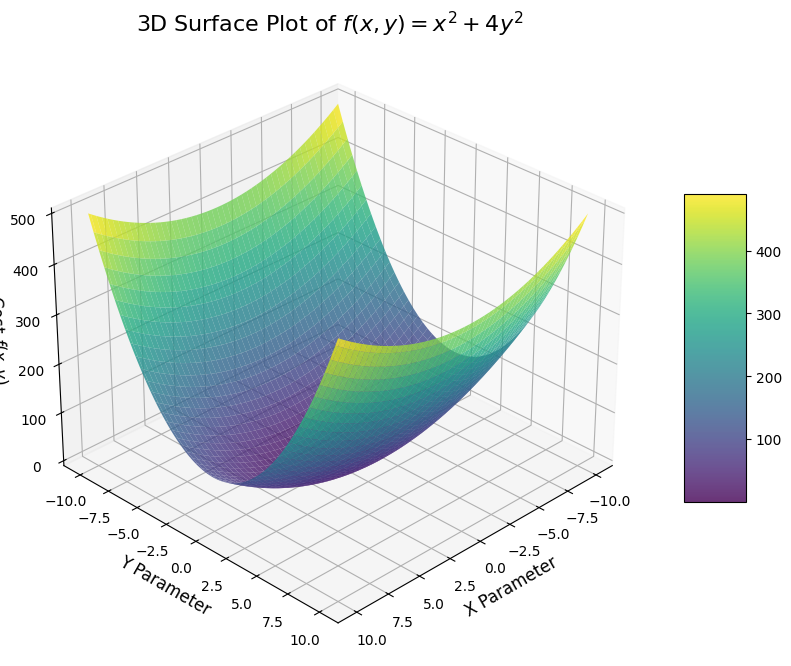

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

# Define the function
def f(x, y):
    return x**2 + 4 * y**2

# Generate grid data
x_val = np.linspace(-10, 10, 100)
y_val = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x_val, y_val)
Z = f(X, Y)

# Create a 3D plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
surf = ax.plot_surface(X, Y, Z, cmap=cm.viridis, edgecolor='none', alpha=0.8)

# Labels and titles
ax.set_title('3D Surface Plot of $f(x, y) = x^2 + 4y^2$', fontsize=16)
ax.set_xlabel('X Parameter', fontsize=12)
ax.set_ylabel('Y Parameter', fontsize=12)
ax.set_zlabel('Cost $f(x, y)$', fontsize=12)

# Add a color bar
fig.colorbar(surf, shrink=0.5, aspect=5)

# Adjust view angle
ax.view_init(elev=30, azim=45)

plt.show()

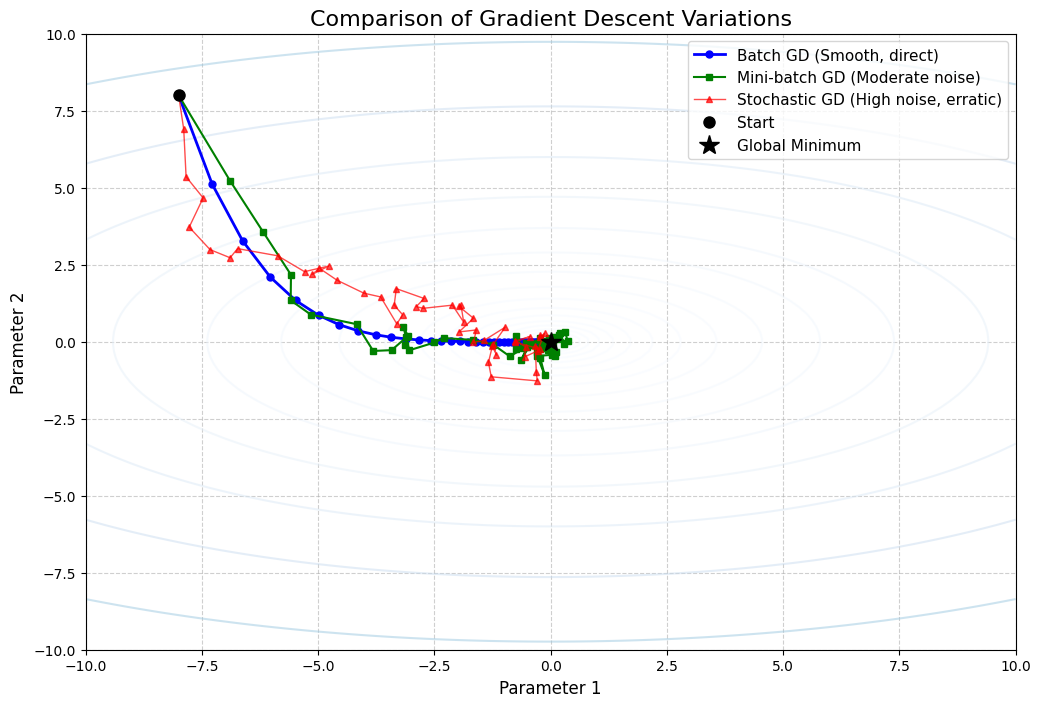

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define a simple cost function (elliptical bowl) and its gradient
def f(x, y):
    return x**2 + 4 * y**2

def grad_f(x, y):
    return np.array([2*x, 8*y])

# Generate data for the contour plot
x_val = np.linspace(-10, 10, 100)
y_val = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x_val, y_val)
Z = f(X, Y)

# Simulation parameters
start_point = np.array([-8.0, 8.0])
lr = 0.045 # Learning rate
iterations = 50

# Arrays to store the paths
path_bgd = [start_point.copy()]
path_sgd = [start_point.copy()]
path_mbgd = [start_point.copy()]

np.random.seed(42) # For reproducibility

# 1. Simulate Batch Gradient Descent (No noise)
curr = start_point.copy()
for _ in range(iterations):
    grad = grad_f(curr[0], curr[1])
    curr = curr - lr * grad
    path_bgd.append(curr.copy())

# 2. Simulate Stochastic Gradient Descent (High noise)
curr = start_point.copy()
for _ in range(iterations):
    # Simulate high variance by adding large random noise to the gradient
    grad = grad_f(curr[0], curr[1]) + np.random.normal(scale=20.0, size=2)
    curr = curr - (lr * 0.4) * grad # smaller lr to prevent divergence
    path_sgd.append(curr.copy())

# 3. Simulate Mini-batch Gradient Descent (Medium noise)
curr = start_point.copy()
for _ in range(iterations):
    # Simulate medium variance by adding moderate random noise
    grad = grad_f(curr[0], curr[1]) + np.random.normal(scale=6.0, size=2)
    curr = curr - lr * grad
    path_mbgd.append(curr.copy())

# Convert to numpy arrays for plotting
path_bgd = np.array(path_bgd)
path_sgd = np.array(path_sgd)
path_mbgd = np.array(path_mbgd)

# Create the plot
plt.figure(figsize=(12, 8))
plt.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='Blues', alpha=0.5)

# Plot the paths
plt.plot(path_bgd[:, 0], path_bgd[:, 1], 'b-o', label='Batch GD (Smooth, direct)', markersize=5, linewidth=2)
plt.plot(path_mbgd[:, 0], path_mbgd[:, 1], 'g-s', label='Mini-batch GD (Moderate noise)', markersize=4, linewidth=1.5)
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'r-^', label='Stochastic GD (High noise, erratic)', markersize=4, linewidth=1, alpha=0.7)

# Mark the start and the minimum
plt.plot(start_point[0], start_point[1], 'ko', markersize=8, label='Start')
plt.plot(0, 0, 'k*', markersize=15, label='Global Minimum')

plt.title('Comparison of Gradient Descent Variations', fontsize=16)
plt.xlabel('Parameter 1', fontsize=12)
plt.ylabel('Parameter 2', fontsize=12)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Detailed Breakdown of the Comparison Plot

The contour plot above simulates and visualizes how different optimization algorithms navigate a 2D loss surface (an elliptical bowl) toward the global minimum at `(0, 0)`:

1. **Batch Gradient Descent (Blue Path - Smooth & Direct)**
   * **Trajectory:** Smooth, steady, and straight toward the minimum. It exhibits virtually no random oscillation.
   * **Why?** Since it calculates the exact gradient of the cost function across the entire dataset at each step, the step direction is mathematically optimal for that point, steering directly down the steepest slope.
   * **Trade-off:** Stable and guaranteed to converge to the minimum for convex surfaces, but extremely slow and memory-intensive when scaling to millions of data points.

2. **Stochastic Gradient Descent (Red Path - Highly Erratic)**
   * **Trajectory:** Highly jagged, chaotic, and seemingly bouncing around, sometimes even moving temporarily away from the minimum.
   * **Why?** Instead of the true gradient, it calculates the gradient using only a single, randomly chosen sample at each step. This single sample acts as a noisy approximation of the entire dataset. This noise introduces high variance into the parameter updates.
   * **Trade-off:** Extremely fast to calculate per iteration. The inherent noise can also help the optimizer escape poor local minima in non-convex landscapes (such as neural networks). However, it never perfectly settles at the exact minimum unless the learning rate is gradually decayed.

3. **Mini-batch Gradient Descent (Green Path - Balanced & Moderate Noise)**
   * **Trajectory:** A moderately noisy path that remains much tighter to the ideal Batch GD trajectory than SGD does.
   * **Why?** It calculates gradients over a small subset (e.g., batch size of 16, 32, or 64) of the training dataset. This reduces the variance of the parameter updates compared to SGD while avoiding the computational overhead of BGD.
   * **Trade-off:** It represents the gold standard in modern deep learning because it is highly compatible with GPU parallelization, computationally efficient, and preserves enough noise to navigate complex loss landscapes successfully.

## Self-Test Questions and Answers


**Question 1: SGD vs. Batch Gradient Descent**
In the context of Matrix Factorization, what is the main difference between Stochastic Gradient Descent (SGD) and Batch Gradient Descent (BGD) regarding how often the parameters are updated?

**Question 2: Regularization**
What is the purpose of the regularization parameter $\lambda$ in the cost function?

**Question 3: User and Item Biases**
Why is it important to include bias terms $b_u$ (user bias) and $b_i$ (item bias) in the model?

**Question 4: Calculation Exercise**
Suppose we have the following learned parameters:
- Global mean $\mu = 3.5$
- User bias $b_u = 0.5$
- Item bias $b_i = -0.2$
- User latent vector $p_u = [0.4, 0.1]$
- Item latent vector $q_i = [1.0, -2.0]$

What is the predicted rating $\hat{r}_{ui}$?

**Question 5: Training Calculation Exercise (Stochastic Gradient Descent Update)**
Suppose you are performing Stochastic Gradient Descent (SGD) for Matrix Factorization. You have the following parameters and hyperparameters at a specific step for user $u$ and item $i$:
- Global mean $\mu = 3.5$
- Current User bias $b_u = 0.5$
- Current Item bias $b_i = -0.2$
- Current User latent vector $p_u = [0.4, 0.1]$
- Current Item latent vector $q_i = [1.0, -2.0]$
- Actual rating $r_{ui} = 4.5$
- Learning rate $\alpha = 0.01$
- Regularization parameter $\lambda = 0.1$

What is the updated value of the user bias $b_u$ after one SGD step?

**Question 6: SGD vs. Batch GD Update Count**
Suppose that user A appears in 200 rows in the user-item preferences dataset. In a single epoch, how many updates will there be to the latent vector $p_u$ in Stochastic Gradient Descent (SGD) versus Batch Gradient Descent (BGD)?

---

### --- Answers ---

**Answer 1:**
In SGD, parameters ($p_u, q_i, b_u, b_i$) are updated after processing each individual rating (preference). In BGD, parameters are updated only after calculating the gradient over all relevant ratings (e.g., all items rated by user $u$ or all users who rated item $i$). This generally makes SGD converge faster for large, sparse datasets.

**Answer 2:**
The regularization parameter $\lambda$ prevents overfitting by penalizing large values in the latent factor vectors and biases. It adds a term to the cost function proportional to the magnitude (squared norm) of the parameters. This encourages the model to learn simpler patterns and generalize better to unseen data.

**Answer 3:**
Bias terms capture effects that are independent of specific user-item interactions. $b_u$ accounts for a user's tendency to rate everything high or low (e.g., a critical user vs. a generous one), and $b_i$ accounts for an item's general popularity or quality (e.g., a blockbuster movie vs. a flop). Modeling these explicitly allows the latent factors to focus on true interaction preferences.

**Answer 4:**
The prediction formula is: $\hat{r}_{ui} = \mu + b_u + b_i + p_u \cdot q_i$

Dot product $p_u \cdot q_i = (0.4 \times 1.0) + (0.1 \times -2.0) = 0.4 - 0.2 = 0.2$

$\hat{r}_{ui} = 3.5 + 0.5 - 0.2 + 0.2 = 4.0$

**Answer 5:**
The prediction formula is: $\hat{r}_{ui} = \mu + b_u + b_i + p_u \cdot q_i$

1.  **Calculate the dot product $p_u \cdot q_i$:**
    $p_u \cdot q_i = (0.4 \times 1.0) + (0.1 \times -2.0) = 0.4 - 0.2 = 0.2$
2.  **Calculate the predicted rating $\hat{r}_{ui}$:**
    $\hat{r}_{ui} = 3.5 + 0.5 + (-0.2) + 0.2 = 4.0$
3.  **Calculate the error $e_{ui}$:**
    $e_{ui} = r_{ui} - \hat{r}_{ui} = 4.5 - 4.0 = 0.5$
4.  **Apply the SGD update rule for $b_u$:**
    $b_u \leftarrow b_u + \alpha (e_{ui} - \lambda b_u)$
    $b_u \leftarrow 0.5 + 0.01 (0.5 - 0.1 \times 0.5)$
    $b_u \leftarrow 0.5 + 0.01 (0.5 - 0.05)$
    $b_u \leftarrow 0.5 + 0.01 (0.45)$
    $b_u \leftarrow 0.5 + 0.0045$
    $b_u = 0.5045$

The updated user bias $b_u$ is $0.5045$.

**Answer 6:**
*   **Stochastic Gradient Descent (SGD):** In SGD, parameters are updated for each individual training example. If user A appears in 200 rows, the latent vector $p_u$ for user A will be updated **200 times** (once for each rating involving user A).
*   **Batch Gradient Descent (BGD):** In BGD, parameters are updated only once per epoch after considering all relevant training examples. For user A, all 200 ratings involving user A will be used to calculate the gradient, but the latent vector $p_u$ will be updated only **1 time** at the end of the epoch.